# Your photo as data

Booster LEAP, Computer Vision, topic 1. What is inside a photograph, what do resizing and JPEG do to it, and how do colour spaces describe it?

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU. It loads three real photographs from our public GitHub repository (an internet connection is needed, Colab has one). Photos: china.jpg and flower.jpg are scikit-learn sample images (Flickr users danielbuechele and vultilion, CC BY 2.0); grace_hopper.jpg is a U.S. Navy photograph, public domain. Change one thing at a time and run again; the last cell tells you what to try, including your own photo.

## 1. Load a photo and look at the numbers

A photograph is an array of numbers: height x width x 3 channels (red, green, blue), each 0 to 255. Run the cell, then look at the shape and at the picture.

china shape (height, width, channels): (427, 640, 3)  dtype: uint8  values 0 to 255


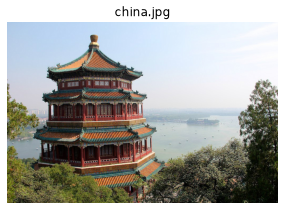

In [ ]:
import io, urllib.request
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/boosterleap/booster-leap-notebooks/main/computer-vision/images/"
FILES = {"china": "china.jpg", "flower": "flower.jpg", "hopper": "grace_hopper.jpg"}

def load_photo(name):
    """one of the three photos of the course, as a PIL image"""
    data = urllib.request.urlopen(BASE + FILES[name]).read()
    return Image.open(io.BytesIO(data)).convert("RGB")

# Your own photo (optional): remove the # signs, run the cell, choose a file.
# from google.colab import files
# photo = Image.open(next(iter(files.upload()))).convert("RGB")

NAME = "china"          # change to "flower" or "hopper"
photo = load_photo(NAME)
img = np.asarray(photo)
print(NAME, "shape (height, width, channels):", img.shape, " dtype:", img.dtype, " values", img.min(), "to", img.max())

plt.figure(figsize=(5, 3.4)); plt.imshow(img); plt.axis("off"); plt.title(f"{NAME}.jpg"); plt.show()

## 2. Channels

Each channel is a grey picture of how much red, green or blue light there is. The histograms show how often each value occurs. The means tell you the average colour.

red   mean  144.7   darkest   0   brightest 255
green mean  145.5   darkest   0   brightest 255
blue  mean  140.9   darkest   0   brightest 255


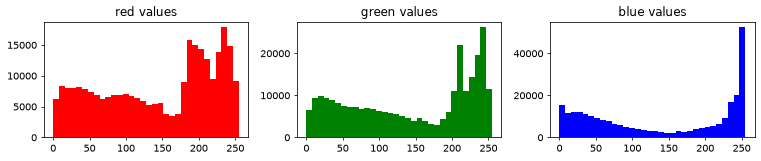

In [ ]:
for c, col in enumerate(["red", "green", "blue"]):
    print(f"{col:5s} mean {img[..., c].mean():6.1f}   darkest {img[..., c].min():3d}   brightest {img[..., c].max():3d}")
fig, ax = plt.subplots(1, 3, figsize=(11, 2.4))
for c, col in enumerate(["red", "green", "blue"]):
    ax[c].hist(img[..., c].ravel(), bins=32, color=col); ax[c].set_title(col + " values")
plt.tight_layout(); plt.show()

## 3. Resolution: what shrinking loses

We shrink the photo to a square of a given side, enlarge it back to the original size and measure the mean absolute difference per number. The error is what the network can never see again.

side 224:  150528 numbers, mean absolute error after enlarging back: 11.35
side 112:   37632 numbers, mean absolute error after enlarging back: 13.97
side  56:    9408 numbers, mean absolute error after enlarging back: 16.69
side  28:    2352 numbers, mean absolute error after enlarging back: 19.78


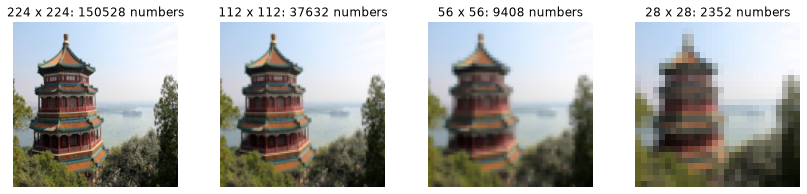

In [ ]:
H, W = img.shape[:2]
sides = [224, 112, 56, 28]
errors = []
fig, ax = plt.subplots(1, len(sides), figsize=(12, 2.8))
for k, s in enumerate(sides):
    small = photo.resize((s, s), Image.BILINEAR)
    back = np.asarray(small.resize((W, H), Image.BILINEAR)).astype(float)
    errors.append(np.abs(back - img).mean())
    ax[k].imshow(small); ax[k].axis("off"); ax[k].set_title(f"{s} x {s}: {s * s * 3} numbers")
    print(f"side {s:3d}: {s * s * 3:7d} numbers, mean absolute error after enlarging back: {errors[-1]:.2f}")
plt.tight_layout(); plt.show()

## 4. JPEG quality: file size against error

A JPEG file keeps only some of the frequencies of every 8 x 8 block. A lower quality gives a smaller file and a bigger error. PSNR (peak signal to noise ratio, in dB) is a standard score: higher means closer to the original.

quality  file size   PSNR (dB)
     95    138.5 KB     36.30
     75     59.7 KB     30.03
     50     39.9 KB     27.12
     25     25.3 KB     24.93
     10     14.0 KB     22.71
      5      9.0 KB     21.02
uncompressed array: 801 KB


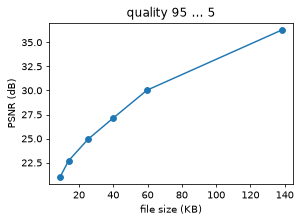

In [ ]:
def jpeg_roundtrip(q):
    b = io.BytesIO(); photo.save(b, format="JPEG", quality=q)
    return b.tell(), np.asarray(Image.open(io.BytesIO(b.getvalue())).convert("RGB")).astype(float)

print("quality  file size   PSNR (dB)")
sizes, psnrs = [], []
for q in [95, 75, 50, 25, 10, 5]:
    size, back = jpeg_roundtrip(q)
    mse = ((back - img.astype(float)) ** 2).mean()
    sizes.append(size / 1024); psnrs.append(10 * np.log10(255 ** 2 / mse))
    print(f"{q:7d}  {size / 1024:7.1f} KB  {psnrs[-1]:8.2f}")
raw = img.size / 1024
print(f"uncompressed array: {raw:.0f} KB")
plt.figure(figsize=(4.5, 3)); plt.plot(sizes, psnrs, "o-"); plt.xlabel("file size (KB)"); plt.ylabel("PSNR (dB)"); plt.title("quality 95 ... 5"); plt.show()

## 5. Colour spaces

The same pixels can be described by hue, saturation and value (HSV), or reduced to one grey channel. The standard grey uses weights (0.299, 0.587, 0.114) because the eye is most sensitive to green. The plain mean of the three channels gives a different grey.

hue mean  141.8 degrees (Pillow stores hue 0..255), saturation mean 0.270, value mean 0.618
luma grey mean 144.7, plain mean grey 143.7, largest difference per pixel 28.1


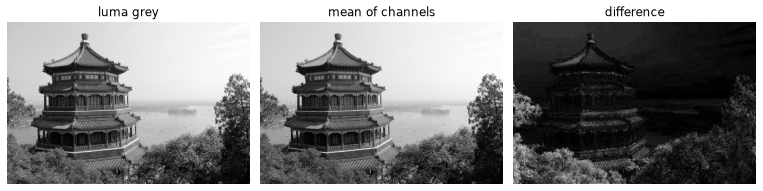

In [ ]:
hsv = np.asarray(photo.convert("HSV")).astype(float)
print(f"hue mean {hsv[..., 0].mean() * 360 / 255:6.1f} degrees (Pillow stores hue 0..255), saturation mean {hsv[..., 1].mean() / 255:.3f}, value mean {hsv[..., 2].mean() / 255:.3f}")
luma = img @ np.array([0.299, 0.587, 0.114])
plain = img.mean(axis=2)
print(f"luma grey mean {luma.mean():.1f}, plain mean grey {plain.mean():.1f}, largest difference per pixel {np.abs(luma - plain).max():.1f}")
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
for a, im, t in zip(ax, [luma, plain, np.abs(luma - plain)], ["luma grey", "mean of channels", "difference"]):
    a.imshow(im, cmap="gray"); a.axis("off"); a.set_title(t)
plt.tight_layout(); plt.show()

## Try it yourself

1. Set `NAME` to `"flower"` and run all cells again. Which channel has the largest mean? Why does the flower photo have such a different histogram from the pagoda?
2. In section 3, add `14` to `sides`. At which side does the error stop growing quickly?
3. In section 4, compare quality 75 for the three photos. Which photo compresses best (smallest file for similar PSNR), and why?
4. Use your own photo: remove the `#` signs in the first cell. Is your photo's average colour the one you expected?
5. Write one sentence for each of the three questions a photo must answer before it goes into a model: size, channel order and value range.